In [180]:
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
import pandas as pd
import numpy as np
%matplotlib inline

In [181]:
X, y = make_blobs(n_samples=1000, centers=3, n_features=2)

In [182]:
X

array([[ 6.4445867 , -7.33929598],
       [ 7.98243898,  1.56401463],
       [ 2.13175099, -8.05210193],
       ...,
       [ 9.43041979, -7.912372  ],
       [10.86930846, -8.69425968],
       [ 5.37023461, -7.54323737]], shape=(1000, 2))

In [183]:
y

array([2, 0, 2, 1, 1, 1, 1, 0, 2, 1, 2, 2, 2, 1, 1, 2, 2, 1, 2, 2, 1, 1,
       2, 2, 2, 0, 1, 0, 2, 0, 1, 2, 2, 0, 1, 2, 0, 1, 2, 2, 0, 1, 2, 2,
       0, 2, 0, 1, 1, 2, 0, 2, 1, 1, 2, 0, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1,
       2, 1, 2, 2, 2, 0, 0, 1, 2, 1, 0, 2, 0, 0, 0, 2, 1, 0, 2, 2, 0, 1,
       2, 2, 0, 2, 1, 2, 0, 1, 2, 2, 2, 0, 0, 2, 0, 0, 2, 2, 1, 1, 0, 0,
       2, 1, 1, 2, 2, 2, 0, 0, 1, 1, 1, 1, 0, 0, 1, 2, 2, 2, 2, 0, 2, 1,
       0, 0, 2, 0, 2, 1, 2, 2, 2, 1, 2, 2, 2, 0, 1, 0, 2, 2, 1, 0, 2, 2,
       2, 2, 0, 1, 0, 0, 2, 1, 2, 2, 1, 1, 0, 2, 0, 2, 2, 1, 0, 2, 0, 0,
       1, 0, 0, 0, 0, 1, 1, 1, 0, 1, 2, 2, 1, 1, 0, 1, 1, 1, 2, 0, 1, 1,
       1, 2, 0, 0, 2, 0, 1, 1, 1, 2, 1, 0, 0, 0, 1, 1, 0, 2, 0, 2, 2, 2,
       1, 2, 1, 2, 1, 2, 1, 0, 2, 2, 0, 0, 0, 2, 1, 0, 2, 0, 1, 0, 2, 1,
       1, 2, 1, 2, 1, 2, 1, 0, 0, 1, 1, 0, 1, 1, 0, 2, 2, 0, 1, 2, 2, 1,
       1, 2, 0, 0, 0, 1, 1, 0, 0, 2, 0, 2, 0, 0, 1, 1, 0, 0, 2, 0, 1, 1,
       1, 0, 1, 0, 1, 0, 1, 1, 0, 1, 2, 2, 2, 2, 2,

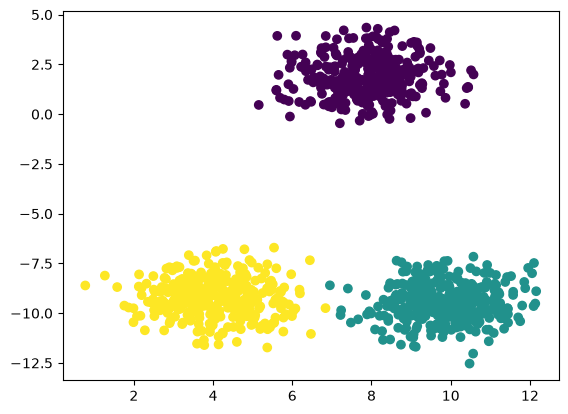

In [184]:
plt.scatter(X[:,0], X[:,1], c=y)

In [185]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

In [186]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.33, random_state=42
)

In [187]:
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [188]:
from sklearn.cluster import KMeans

In [189]:
## Elbow method to sleect K value

wcss =[]
for k in range(1,11):
    kmeans = KMeans(n_clusters=k, init="k-means++")
    kmeans.fit(X_train_scaled)
    wcss.append(kmeans.inertia_)

In [190]:
wcss # wcss value with respect to 1-10

[1340.0000000000002,
 803.335651152787,
 116.8171702435827,
 94.35971437949381,
 89.0812901344974,
 71.6629320728347,
 50.783376877573886,
 45.898375513925146,
 42.61425993500556,
 38.12978828447413]

Text(0, 0.5, '[1340.0000000000002, 803.335651152787, 116.8171702435827, 94.35971437949381, 89.0812901344974, 71.6629320728347, 50.783376877573886, 45.898375513925146, 42.61425993500556, 38.12978828447413]')

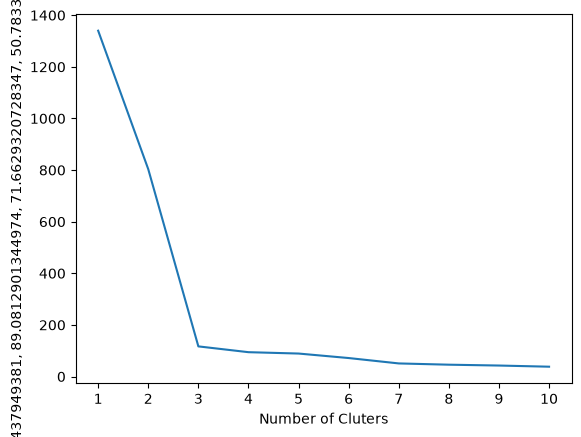

In [191]:
# Plot elbow curve

plt.plot(range(1,11), wcss)
plt.xticks(range(1,11))
plt.xlabel("Number of Cluters")
plt.ylabel(wcss)

In [192]:
kmeans=KMeans(n_clusters=3, init="k-means++")

In [193]:
kmeans.fit_predict(X_train_scaled)

array([2, 0, 0, 1, 0, 1, 2, 1, 0, 1, 2, 1, 1, 0, 1, 2, 1, 0, 1, 0, 2, 1,
       1, 0, 1, 2, 0, 2, 1, 0, 1, 1, 1, 2, 2, 0, 2, 2, 2, 1, 0, 2, 0, 0,
       2, 2, 2, 2, 1, 0, 2, 1, 1, 2, 2, 2, 1, 1, 2, 2, 2, 2, 1, 1, 1, 2,
       2, 2, 1, 2, 0, 1, 1, 2, 1, 1, 0, 0, 0, 1, 2, 1, 2, 2, 0, 0, 1, 2,
       1, 1, 0, 1, 2, 1, 2, 0, 1, 2, 1, 1, 2, 1, 0, 1, 2, 0, 2, 2, 2, 1,
       0, 2, 0, 1, 1, 1, 2, 2, 2, 1, 1, 1, 1, 0, 2, 0, 0, 2, 0, 2, 0, 0,
       0, 2, 0, 0, 0, 0, 0, 0, 0, 2, 0, 0, 2, 1, 0, 1, 2, 1, 0, 1, 0, 1,
       0, 0, 0, 0, 0, 0, 2, 1, 2, 1, 2, 1, 1, 2, 1, 1, 2, 1, 0, 0, 1, 0,
       0, 0, 1, 2, 0, 1, 0, 0, 1, 0, 2, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1,
       1, 0, 2, 0, 0, 2, 1, 0, 0, 2, 0, 2, 2, 1, 0, 0, 1, 1, 0, 0, 1, 0,
       1, 0, 2, 1, 2, 2, 0, 1, 1, 1, 1, 0, 1, 2, 2, 2, 0, 2, 0, 1, 0, 2,
       2, 1, 1, 2, 0, 2, 2, 2, 2, 0, 0, 2, 1, 2, 0, 2, 0, 1, 0, 2, 2, 2,
       1, 0, 1, 0, 2, 0, 2, 0, 0, 2, 2, 2, 1, 0, 0, 0, 1, 1, 1, 2, 1, 0,
       1, 1, 1, 0, 2, 2, 2, 2, 0, 2, 2, 1, 1, 2, 1,

In [194]:
y_pred = kmeans.predict(X_test_scaled)

In [195]:
y_pred

array([1, 1, 2, 1, 2, 1, 1, 0, 1, 0, 0, 1, 0, 2, 1, 1, 1, 1, 2, 2, 0, 1,
       0, 2, 1, 1, 0, 0, 2, 2, 1, 0, 2, 0, 1, 2, 1, 0, 1, 2, 1, 0, 1, 2,
       0, 1, 0, 2, 0, 0, 0, 0, 0, 1, 0, 2, 2, 0, 0, 0, 0, 0, 1, 1, 1, 0,
       1, 1, 0, 1, 2, 0, 2, 2, 2, 1, 0, 0, 1, 0, 0, 0, 0, 2, 0, 2, 2, 0,
       2, 2, 0, 0, 1, 0, 1, 1, 1, 0, 1, 1, 2, 1, 2, 1, 1, 1, 0, 0, 1, 0,
       0, 0, 1, 0, 1, 2, 1, 2, 0, 1, 1, 1, 0, 2, 1, 2, 1, 0, 1, 0, 1, 1,
       0, 2, 2, 1, 2, 0, 1, 1, 1, 0, 2, 1, 0, 2, 2, 2, 1, 2, 2, 1, 0, 2,
       0, 2, 0, 1, 2, 2, 0, 2, 1, 1, 2, 1, 0, 2, 1, 0, 0, 2, 0, 2, 0, 0,
       2, 1, 1, 0, 1, 1, 2, 2, 0, 2, 0, 1, 0, 1, 1, 1, 2, 0, 2, 0, 0, 2,
       1, 1, 1, 1, 1, 1, 2, 0, 2, 2, 1, 0, 2, 2, 0, 1, 0, 1, 2, 1, 0, 2,
       0, 0, 1, 0, 1, 0, 0, 2, 0, 2, 2, 0, 2, 0, 1, 0, 1, 1, 2, 0, 2, 2,
       0, 0, 2, 1, 1, 0, 0, 2, 2, 1, 2, 2, 1, 0, 1, 1, 0, 2, 1, 1, 0, 1,
       2, 1, 0, 2, 0, 1, 2, 2, 1, 1, 0, 2, 2, 2, 0, 1, 2, 0, 1, 2, 1, 1,
       2, 1, 1, 0, 2, 0, 1, 1, 1, 1, 0, 0, 1, 0, 0,

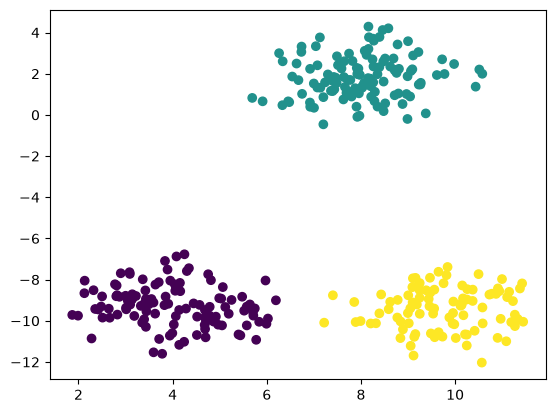

In [196]:
plt.scatter(X_test[:,0], X_test[:,1], c=y_pred)

In [199]:
## Validating the K value
# 1. kneelocator
# 2. Sihoutte Scoring

In [200]:
## Knee Locator
!pip install kneed

In [205]:
from kneed import KneeLocator

In [208]:
kl = KneeLocator(range(1,11), wcss, curve="convex", direction="decreasing")
kl.elbow


np.int64(3)

In [209]:
## Silhoutte scoring
from sklearn.metrics import silhouette_score

In [210]:
silhouette_coefficients=[]
for k in range(2,11):
    kmeans=KMeans(n_clusters=k,init="k-means++")
    kmeans.fit(X_train_scaled)
    score=silhouette_score(X_train_scaled,kmeans.labels_)
    silhouette_coefficients.append(score)

In [211]:
silhouette_coefficients

[0.5204067573374819,
 0.7642208317402926,
 0.64191592130587,
 0.5435904965203687,
 0.5123969598587526,
 0.40900434148822734,
 0.375008227538829,
 0.3779725207220554,
 0.3761486090050381]

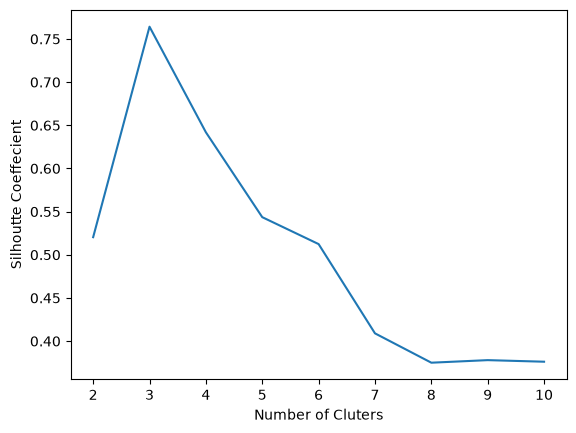

In [212]:
## plotting silhouette score
plt.plot(range(2,11),silhouette_coefficients)
plt.xticks(range(2,11))
plt.xlabel("Number of Cluters")
plt.ylabel("Silhoutte Coeffecient")
plt.show()